<a href="https://colab.research.google.com/github/amannegi133/Aman-Negi-2026B03110166-/blob/main/Aman_Negi_2026B03110166.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 25: Water Usage & Conservation Analysis
**Industry:** Environment / Public Utilities  
**Level:** Beginner | Python, Pandas, NumPy, Matplotlib

**Business scenario:** Analyze household and building water-meter readings to understand consumption patterns, identify high usage and suggest conservation measures.

> **Dataset note:** `25_water_consumption.csv` contains 1,000 meter readings from 100 households (10 consecutive monthly readings each, Jan 2025 – Oct 2026). The values are simulated for this exercise, so describe patterns as *associations in this dataset*, not as real-world facts.

**How to run in Google Colab:** upload this notebook to Colab, run the first code cell, and upload `25_water_consumption.csv` when prompted. Then use **Runtime → Run all**.

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)
pd.set_option("display.float_format", "{:,.1f}".format)

FILE = "25_water_consumption.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        print("Please upload 25_water_consumption.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place {FILE} in the same folder as this notebook.")

Please upload 25_water_consumption.csv


Saving 25_water_consumption.csv to 25_water_consumption.csv


## Task 1: Load the dataset and inspect dimensions, columns and data types

In [2]:
df = pd.read_csv(FILE)
print("Shape (rows, columns):", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
df.head()

Shape (rows, columns): (1000, 7)

Columns: ['Meter_Record_ID', 'Household_ID', 'Reading_Date', 'Household_Type', 'Building_Type', 'Zone', 'Water_Usage_Liters']

Data types:
Meter_Record_ID        object
Household_ID           object
Reading_Date           object
Household_Type         object
Building_Type          object
Zone                   object
Water_Usage_Liters    float64
dtype: object


,Meter_Record_ID,Household_ID,Reading_Date,Household_Type,Building_Type,Zone,Water_Usage_Liters
0,WM000000,HH00247,2026-09-20,Apartment,Commercial,Zone E,"3,287.1"
1,WM000001,HH00026,2026-06-19,Hostel,Commercial,Zone D,"8,044.1"
2,WM000002,HH00108,2026-02-06,Villa,Commercial,Zone E,"5,155.0"
3,WM000003,HH00249,2026-07-09,Apartment,Commercial,Zone C,"5,792.3"
4,WM000004,HH00295,2025-11-05,Apartment,Commercial,Zone D,"4,077.9"


## Task 2: Identify missing values and duplicate `Meter_Record_ID` entries

In [3]:
print("Missing values per column:")
print(df.isna().sum())

dup_ids = df["Meter_Record_ID"].duplicated().sum()
dup_rows = df.duplicated().sum()
print("\nDuplicate Meter_Record_ID entries:", dup_ids)
print("Fully duplicated rows:", dup_rows)

# Remove duplicates (none expected here, but the step keeps the pipeline safe)
df = df.drop_duplicates(subset="Meter_Record_ID").reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Missing values per column:
Meter_Record_ID        0
Household_ID           0
Reading_Date           0
Household_Type         0
Building_Type          0
Zone                   0
Water_Usage_Liters    22
dtype: int64

Duplicate Meter_Record_ID entries: 0
Fully duplicated rows: 0
Rows after removing duplicates: 1000


## Task 3: Handle missing `Water_Usage_Liters` values

**Method chosen: fill with the median usage of the same Household_Type.**  
*Why:* the median is not pulled up by very high readings (leaks, spikes), and grouping by household type keeps the filled value close to what a similar household would use. Dropping the rows instead would lose about 2% of the data for no good reason.

In [4]:
missing_before = df["Water_Usage_Liters"].isna().sum()
df["Water_Usage_Liters"] = df["Water_Usage_Liters"].fillna(
    df.groupby("Household_Type")["Water_Usage_Liters"].transform("median")
)
print("Missing before:", missing_before, "| Missing after:", df["Water_Usage_Liters"].isna().sum())

Missing before: 22 | Missing after: 0


## Task 4: Convert `Reading_Date` to datetime and extract month and weekday

In [5]:
df["Reading_Date"] = pd.to_datetime(df["Reading_Date"])
df["Year"] = df["Reading_Date"].dt.year
df["Month_Num"] = df["Reading_Date"].dt.month
df["Month"] = df["Reading_Date"].dt.month_name()
df["Weekday"] = df["Reading_Date"].dt.day_name()
df["YearMonth"] = df["Reading_Date"].dt.to_period("M")

print(df["Reading_Date"].min().date(), "to", df["Reading_Date"].max().date())
df[["Reading_Date", "Year", "Month", "Weekday", "YearMonth"]].head()

2025-01-02 to 2026-10-30


,Reading_Date,Year,Month,Weekday,YearMonth
0,2026-09-20,2026,September,Sunday,2026-09
1,2026-06-19,2026,June,Friday,2026-06
2,2026-02-06,2026,February,Friday,2026-02
3,2026-07-09,2026,July,Thursday,2026-07
4,2025-11-05,2025,November,Wednesday,2025-11


## Task 5: Total consumption and average consumption per household

In [6]:
total_consumption = df["Water_Usage_Liters"].sum()
household_total = df.groupby("Household_ID")["Water_Usage_Liters"].sum()

print(f"Total water consumption: {total_consumption:,.1f} liters")
print(f"Number of households: {household_total.shape[0]}")
print(f"Average total consumption per household: {household_total.mean():,.1f} liters")
print(f"Average usage per meter reading: {df['Water_Usage_Liters'].mean():,.1f} liters")

Total water consumption: 6,268,102.0 liters
Number of households: 100
Average total consumption per household: 62,681.0 liters
Average usage per meter reading: 6,268.1 liters


## Task 6: Month-to-month consumption change for each household
Readings are first summed per household per month. The change is calculated only between **consecutive** months, so a gap in readings is never treated as a month-to-month change.

In [7]:
monthly_hh = (
    df.groupby(["Household_ID", "YearMonth"])["Water_Usage_Liters"]
      .sum().reset_index().sort_values(["Household_ID", "YearMonth"])
)
monthly_hh["Month_Index"] = monthly_hh["YearMonth"].apply(lambda p: p.year * 12 + p.month)
g = monthly_hh.groupby("Household_ID")

monthly_hh["Change_Liters"] = g["Water_Usage_Liters"].diff()
monthly_hh["Change_Pct"] = g["Water_Usage_Liters"].pct_change() * 100
gap = g["Month_Index"].diff()
monthly_hh.loc[gap != 1, ["Change_Liters", "Change_Pct"]] = np.nan   # keep only consecutive months

print("Sample of month-to-month changes:")
display_cols = ["Household_ID", "YearMonth", "Water_Usage_Liters", "Change_Liters", "Change_Pct"]
print(monthly_hh[display_cols].head(12).to_string(index=False))

print("\nAverage change per household (liters/month), top 5 increases:")
avg_change = monthly_hh.groupby("Household_ID")["Change_Liters"].mean().sort_values(ascending=False)
print(avg_change.head(5))

Sample of month-to-month changes:
Household_ID YearMonth  Water_Usage_Liters  Change_Liters  Change_Pct
     HH00001   2025-06             9,977.8            NaN         NaN
     HH00001   2025-07             8,505.5       -1,472.3       -14.8
     HH00001   2025-08             7,457.2       -1,048.3       -12.3
     HH00001   2025-09             6,625.6         -831.6       -11.2
     HH00001   2025-10             7,465.9          840.3        12.7
     HH00001   2025-11             6,688.5         -777.4       -10.4
     HH00001   2025-12             4,204.6       -2,483.9       -37.1
     HH00001   2026-01             5,832.3        1,627.7        38.7
     HH00001   2026-02             6,619.5          787.2        13.5
     HH00001   2026-03             7,607.5          988.0        14.9
     HH00006   2025-08             3,661.0            NaN         NaN
     HH00006   2025-09             4,227.5          566.5        15.5

Average change per household (liters/month), top 5 incr

## Task 7: Rank household types by total water usage

In [8]:
type_summary = (
    df.groupby("Household_Type")["Water_Usage_Liters"]
      .agg(Total_Liters="sum", Average_Liters="mean", Readings="count")
      .sort_values("Total_Liters", ascending=False)
)
type_summary["Rank"] = range(1, len(type_summary) + 1)
type_summary

,Total_Liters,Average_Liters,Readings,Rank
Household_Type,,,,
Villa,"1,862,346.6","7,449.4",250,1
Hostel,"1,725,147.8","6,900.6",250,2
Independent,"1,569,721.3","5,813.8",270,3
Apartment,"1,110,886.3","4,829.9",230,4


## Task 8: Compare average consumption across building types and zones

In [9]:
building_avg = df.groupby("Building_Type")["Water_Usage_Liters"].mean().sort_values(ascending=False)
zone_avg = df.groupby("Zone")["Water_Usage_Liters"].mean().sort_values(ascending=False)

print("Average usage by Building_Type:")
print(building_avg)
print("\nAverage usage by Zone:")
print(zone_avg)

Average usage by Building_Type:
Building_Type
Mixed Use     7,121.1
Residential   6,369.2
Commercial    6,102.8
Name: Water_Usage_Liters, dtype: float64

Average usage by Zone:
Zone
Zone B   7,285.3
Zone E   6,225.7
Zone C   6,190.1
Zone D   5,811.9
Zone A   5,784.9
Name: Water_Usage_Liters, dtype: float64


## Task 9: The 10 households with the highest total consumption

In [10]:
top10 = (
    df.groupby("Household_ID")
      .agg(Total_Liters=("Water_Usage_Liters", "sum"),
           Readings=("Water_Usage_Liters", "count"),
           Household_Type=("Household_Type", "first"),
           Zone=("Zone", "first"))
      .sort_values("Total_Liters", ascending=False)
      .head(10)
)
top10

,Total_Liters,Readings,Household_Type,Zone
Household_ID,,,,
HH00061,"121,391.3",10,Hostel,Zone B
HH00097,"103,752.0",10,Villa,Zone B
HH00146,"98,772.6",10,Villa,Zone E
HH00190,"95,884.2",10,Hostel,Zone C
HH00378,"94,457.7",10,Villa,Zone D
HH00237,"94,381.5",10,Hostel,Zone B
HH00119,"93,420.0",10,Villa,Zone E
HH00065,"92,755.6",10,Hostel,Zone D
HH00151,"92,396.3",10,Apartment,Zone C


## Task 10: Month with the highest overall water usage

In [11]:
monthly_total = df.groupby("YearMonth")["Water_Usage_Liters"].agg(Total="sum", Average="mean", Readings="count")
peak_ym = monthly_total["Total"].idxmax()
print(f"Peak month (by total usage): {peak_ym}  ->  {monthly_total.loc[peak_ym, 'Total']:,.1f} liters")

# Calendar-month view (all years combined) - average per reading avoids bias from unequal reading counts
calendar_month = (
    df.groupby(["Month_Num", "Month"])["Water_Usage_Liters"].mean().reset_index().sort_values("Month_Num")
)
peak_cal = calendar_month.loc[calendar_month["Water_Usage_Liters"].idxmax()]
print(f"Highest calendar month by average usage per reading: {peak_cal['Month']} ({peak_cal['Water_Usage_Liters']:,.1f} liters)")
calendar_month

Peak month (by total usage): 2025-10  ->  465,222.8 liters
Highest calendar month by average usage per reading: June (7,694.6 liters)


,Month_Num,Month,Water_Usage_Liters
0,1,January,"5,643.4"
1,2,February,"5,606.6"
2,3,March,"6,092.6"
3,4,April,"6,822.7"
4,5,May,"7,381.3"
5,6,June,"7,694.6"
6,7,July,"6,487.6"
7,8,August,"6,154.7"
8,9,September,"6,106.0"
9,10,October,"5,964.3"


## Task 11: Dictionary of zone-wise totals and a set of unique zones

In [12]:
zone_totals = df.groupby("Zone")["Water_Usage_Liters"].sum().round(1).to_dict()
unique_zones = set(df["Zone"])

print("Zone-wise consumption totals (dict):")
for zone, total in zone_totals.items():
    print(f"  {zone}: {total:,.1f} L")
print("\nUnique zones (set):", unique_zones)
print("Number of unique zones:", len(unique_zones))

Zone-wise consumption totals (dict):
  Zone A: 867,740.4 L
  Zone B: 1,529,911.1 L
  Zone C: 1,114,214.7 L
  Zone D: 1,511,099.1 L
  Zone E: 1,245,136.7 L

Unique zones (set): {'Zone E', 'Zone D', 'Zone C', 'Zone B', 'Zone A'}
Number of unique zones: 5


## Task 12: Classify consumption as Low, Normal or High
**Thresholds (data-driven):**
- **Low:** below the 25th percentile
- **Normal:** between the 25th and 75th percentile (inclusive)
- **High:** above the 75th percentile

In [13]:
LOW_LIMIT, HIGH_LIMIT = np.percentile(df["Water_Usage_Liters"], [25, 75])
print(f"Low < {LOW_LIMIT:,.1f} L | Normal {LOW_LIMIT:,.1f}-{HIGH_LIMIT:,.1f} L | High > {HIGH_LIMIT:,.1f} L")

def classify_consumption(liters, low=LOW_LIMIT, high=HIGH_LIMIT):
    """Return 'Low', 'Normal' or 'High' for a single usage value."""
    if liters < low:
        return "Low"
    elif liters <= high:
        return "Normal"
    return "High"

df["Consumption_Category"] = df["Water_Usage_Liters"].apply(classify_consumption)
print()
print(df["Consumption_Category"].value_counts())
df[["Meter_Record_ID", "Water_Usage_Liters", "Consumption_Category"]].head()

Low < 4,621.6 L | Normal 4,621.6-7,467.1 L | High > 7,467.1 L

Consumption_Category
Normal    500
Low       250
High      250
Name: count, dtype: int64


,Meter_Record_ID,Water_Usage_Liters,Consumption_Category
0,WM000000,"3,287.1",Low
1,WM000001,"8,044.1",High
2,WM000002,"5,155.0",Normal
3,WM000003,"5,792.3",Normal
4,WM000004,"4,077.9",Low


## Task 13: NumPy statistics (mean, median, variance, standard deviation)

In [14]:
usage = df["Water_Usage_Liters"].to_numpy()

print(f"Mean              : {np.mean(usage):,.2f} L")
print(f"Median            : {np.median(usage):,.2f} L")
print(f"Variance          : {np.var(usage):,.2f}")
print(f"Standard deviation: {np.std(usage):,.2f} L")
print(f"Min / Max         : {usage.min():,.1f} / {usage.max():,.1f} L")

Mean              : 6,268.10 L
Median            : 5,916.30 L
Variance          : 5,101,345.52
Standard deviation: 2,258.62 L
Min / Max         : 2,117.7 / 21,808.3 L


## Task 14: Unusually high consumption (IQR method) and average usage by household type
**Rule:** a record is unusually high if it is above `Q3 + 1.5 × IQR`.

In [15]:
Q1, Q3 = np.percentile(df["Water_Usage_Liters"], [25, 75])
IQR = Q3 - Q1
upper_fence = Q3 + 1.5 * IQR
lower_fence = Q1 - 1.5 * IQR
print(f"Q1 = {Q1:,.1f} | Q3 = {Q3:,.1f} | IQR = {IQR:,.1f}")
print(f"Upper fence = {upper_fence:,.1f} L  (lower fence = {lower_fence:,.1f} L)")

high_usage = df[df["Water_Usage_Liters"] > upper_fence].sort_values("Water_Usage_Liters", ascending=False)
print(f"\nUnusually high records: {len(high_usage)} ({len(high_usage) / len(df):.1%} of all readings)")
high_usage[["Meter_Record_ID", "Household_ID", "Reading_Date", "Household_Type", "Zone", "Water_Usage_Liters"]]

Q1 = 4,621.6 | Q3 = 7,467.1 | IQR = 2,845.5
Upper fence = 11,735.4 L  (lower fence = 353.3 L)

Unusually high records: 21 (2.1% of all readings)


,Meter_Record_ID,Household_ID,Reading_Date,Household_Type,Zone,Water_Usage_Liters
472,WM000472,HH00073,2025-06-07,Independent,Zone D,"21,808.3"
817,WM000817,HH00146,2025-07-20,Villa,Zone E,"18,381.8"
100,WM000100,HH00190,2025-08-07,Hostel,Zone C,"17,112.0"
887,WM000887,HH00061,2026-05-03,Hostel,Zone B,"16,003.6"
430,WM000430,HH00146,2025-06-09,Villa,Zone E,"14,082.0"
815,WM000815,HH00027,2026-01-16,Hostel,Zone C,"13,545.3"
161,WM000161,HH00061,2026-04-11,Hostel,Zone B,"13,218.5"
999,WM000999,HH00061,2025-10-17,Hostel,Zone B,"12,945.4"
972,WM000972,HH00061,2025-09-29,Hostel,Zone B,"12,896.4"
795,WM000795,HH00097,2026-06-18,Villa,Zone B,"12,708.2"


In [16]:
type_compare = df.groupby("Household_Type")["Water_Usage_Liters"].agg(["mean", "median", "std", "count"])
type_compare["High_Outliers"] = high_usage.groupby("Household_Type").size()
type_compare["High_Outliers"] = type_compare["High_Outliers"].fillna(0).astype(int)
type_compare.sort_values("mean", ascending=False)

,mean,median,std,count,High_Outliers
Household_Type,,,,,
Villa,"7,449.4","7,072.7","2,040.2",250,7
Hostel,"6,900.6","6,451.4","2,404.0",250,11
Independent,"5,813.8","5,573.1","1,907.3",270,2
Apartment,"4,829.9","4,372.4","1,706.7",230,1


## Visualizations

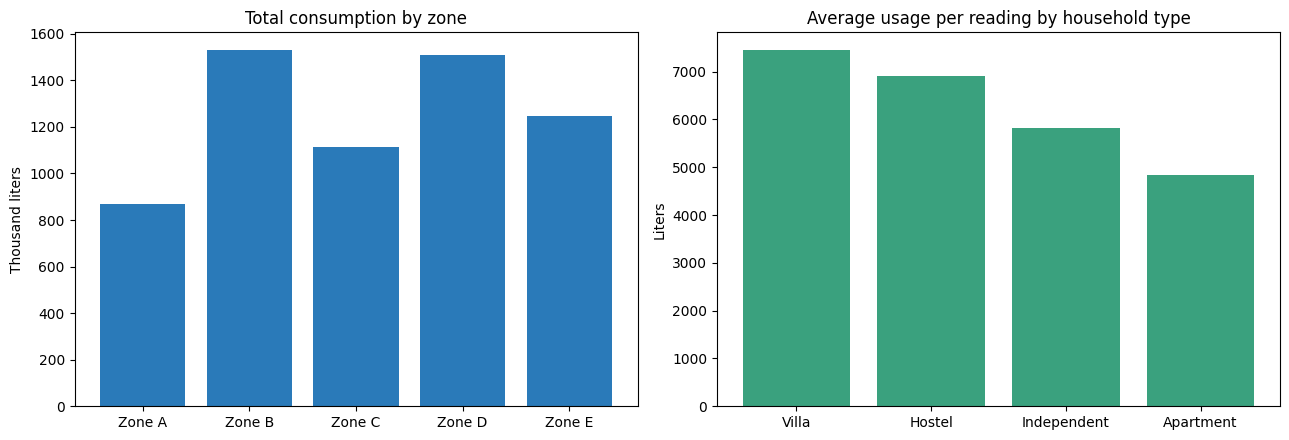

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

zone_tot = df.groupby("Zone")["Water_Usage_Liters"].sum()
axes[0].bar(zone_tot.index, zone_tot.values / 1000, color="#2a7ab9")
axes[0].set_title("Total consumption by zone")
axes[0].set_ylabel("Thousand liters")

type_avg = df.groupby("Household_Type")["Water_Usage_Liters"].mean().sort_values(ascending=False)
axes[1].bar(type_avg.index, type_avg.values, color="#3aa17e")
axes[1].set_title("Average usage per reading by household type")
axes[1].set_ylabel("Liters")
plt.tight_layout(); plt.show()

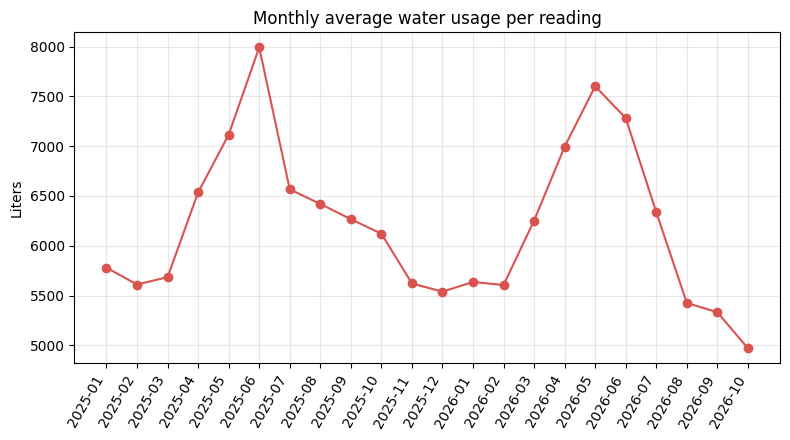

In [18]:
trend = df.groupby("YearMonth")["Water_Usage_Liters"].mean()
plt.plot(trend.index.astype(str), trend.values, marker="o", color="#d9534f")
plt.xticks(rotation=60, ha="right")
plt.title("Monthly average water usage per reading")
plt.ylabel("Liters"); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

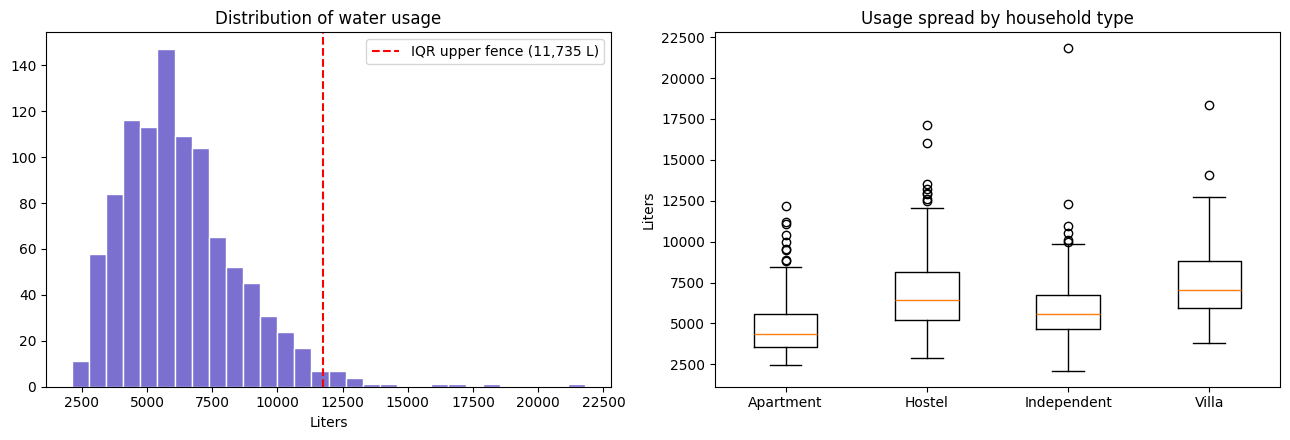

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df["Water_Usage_Liters"], bins=30, color="#7b6fd0", edgecolor="white")
axes[0].axvline(upper_fence, color="red", linestyle="--", label=f"IQR upper fence ({upper_fence:,.0f} L)")
axes[0].set_title("Distribution of water usage"); axes[0].set_xlabel("Liters"); axes[0].legend()

groups = [g["Water_Usage_Liters"].values for _, g in df.groupby("Household_Type")]
axes[1].boxplot(groups)
axes[1].set_xticklabels(sorted(df["Household_Type"].unique()))
axes[1].set_title("Usage spread by household type"); axes[1].set_ylabel("Liters")
plt.tight_layout(); plt.show()

## Task 15: `WaterMeter` class and conservation recommendations

In [20]:
class WaterMeter:
    """A simple water meter with an ID and a household type."""
    def __init__(self, meter_id, household_type):
        self.meter_id = meter_id
        self.household_type = household_type

    def __str__(self):
        return f"Meter {self.meter_id} ({self.household_type})"

# Create meter objects for the 5 highest readings
meters = [WaterMeter(r.Meter_Record_ID, r.Household_Type)
          for r in df.nlargest(5, "Water_Usage_Liters").itertuples()]
for m in meters:
    print(m)

Meter WM000472 (Independent)
Meter WM000817 (Villa)
Meter WM000100 (Hostel)
Meter WM000887 (Hostel)
Meter WM000430 (Villa)


In [21]:
# Values used in the recommendations (computed from the data so the text always matches the results)
top_zone, top_zone_val = zone_avg.index[0], zone_avg.iloc[0]
low_zone, low_zone_val = zone_avg.index[-1], zone_avg.iloc[-1]
top_type, top_type_val = type_avg.index[0], type_avg.iloc[0]
top_building, top_building_val = building_avg.index[0], building_avg.iloc[0]

summer = df[df["Month_Num"].isin([4, 5, 6])]["Water_Usage_Liters"].mean()
winter = df[df["Month_Num"].isin([12, 1, 2])]["Water_Usage_Liters"].mean()
summer_rise = (summer / winter - 1) * 100
high_share = (df["Consumption_Category"] == "High").mean() * 100
top3_hh = ", ".join(top10.index[:3])

print("FIVE WATER-CONSERVATION RECOMMENDATIONS")
print("=" * 60)
print(f"1. Target {top_zone}: it has the highest average usage ({top_zone_val:,.0f} L per reading, "
      f"{(top_zone_val / low_zone_val - 1) * 100:.1f}% above {low_zone}). Prioritise audits and awareness campaigns there.")
print(f"2. Focus on {top_type} households ({top_type_val:,.0f} L per reading on average) and on "
      f"{top_building} buildings ({top_building_val:,.0f} L) with water-efficient fixtures, such as low-flow taps and dual-flush toilets.")
print(f"3. Plan for the summer peak: usage in Apr-Jun is about {summer_rise:.0f}% higher than in Dec-Feb. "
      f"Launch conservation reminders and outdoor-use restrictions before April.")
print(f"4. Run leak inspections for the {len(high_usage)} unusually high readings (above {upper_fence:,.0f} L) and for the "
      f"top consumers ({top3_hh}, ...). Sudden spikes often point to leaks or faulty meters.")
print(f"5. Use tiered pricing or usage alerts for the 'High' band ({high_share:.0f}% of readings above {HIGH_LIMIT:,.0f} L), "
      f"so heavy users get feedback and a financial reason to cut usage.")

FIVE WATER-CONSERVATION RECOMMENDATIONS
1. Target Zone B: it has the highest average usage (7,285 L per reading, 25.9% above Zone A). Prioritise audits and awareness campaigns there.
2. Focus on Villa households (7,449 L per reading on average) and on Mixed Use buildings (7,121 L) with water-efficient fixtures, such as low-flow taps and dual-flush toilets.
3. Plan for the summer peak: usage in Apr-Jun is about 30% higher than in Dec-Feb. Launch conservation reminders and outdoor-use restrictions before April.
4. Run leak inspections for the 21 unusually high readings (above 11,735 L) and for the top consumers (HH00061, HH00097, HH00146, ...). Sudden spikes often point to leaks or faulty meters.
5. Use tiered pricing or usage alerts for the 'High' band (25% of readings above 7,467 L), so heavy users get feedback and a financial reason to cut usage.


## Save the cleaned dataset and a short summary

In [22]:
clean_out = df.copy()
clean_out["YearMonth"] = clean_out["YearMonth"].astype(str)
clean_out.to_csv("25_water_consumption_cleaned.csv", index=False)

with open("water_usage_summary.txt", "w") as f:
    f.write("Water Usage Summary\n")
    f.write("===================\n")
    f.write(f"Records analysed      : {len(df)}\n")
    f.write(f"Households            : {df['Household_ID'].nunique()}\n")
    f.write(f"Total consumption (L) : {total_consumption:,.1f}\n")
    f.write(f"Mean / median (L)     : {np.mean(usage):,.1f} / {np.median(usage):,.1f}\n")
    f.write(f"Peak month (total)    : {peak_ym}\n")
    f.write(f"Highest-usage zone    : {top_zone}\n")
    f.write(f"High-usage records    : {len(high_usage)}\n")
print(open("water_usage_summary.txt").read())

# In Colab, uncomment to download the outputs:
# from google.colab import files
# files.download("25_water_consumption_cleaned.csv"); files.download("water_usage_summary.txt")

Water Usage Summary
Records analysed      : 1000
Households            : 100
Total consumption (L) : 6,268,102.0
Mean / median (L)     : 6,268.1 / 5,916.3
Peak month (total)    : 2025-10
Highest-usage zone    : Zone B
High-usage records    : 21



## Conclusion
- The dataset was cleaned (duplicates checked, missing readings filled with the household-type median) and 1,000 readings were analysed.
- Household type shows the largest gap (Villa about 54% above Apartment per reading), followed by the season (Apr-Jun about 30% above Dec-Feb) and the zone (Zone B about 26% above Zone A). A small number of spikes sit above the IQR fence.
- Highest-usage groups, the peak period and the outliers above give a clear list of where to focus conservation effort.
- Limitations: the data is simulated and covers 100 households, so treat the findings as an exercise in method rather than evidence about real consumption. Patterns shown are associations, not proven causes.